# Evaluation and model selection

## 1. Introduction and learning objectives

Evaluation is a data-use protocol as well as a collection of metrics. Build baselines, measure prediction and decision quality, select models within training data, choose a decision rule on validation data, and evaluate the frozen procedure on test data once. State what uncertainty your experiment does and does not include.

Prerequisites are the first four Stage 01 chapters and the Stage 00 discussion of iid estimation. The demonstrations use tiny declared arrays; the challenges build reusable local evaluation functions without a machine-learning framework.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 01.05.01 — Allocate each decision to data

**Type:** Conceptual · **Answer:** Markdown

You have training, validation, and test partitions. Assign feature scaling, penalty selection by cross-validation, threshold selection, and final reporting to them. Should you refit after selecting the threshold in this delivery?

**Expected outcome:** a concrete sequence that leaves test labels unused until the end.

**Your response to Exercise 01.05.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.01**

Every CV training fold needs its own fitted preprocessing. Changing a fitted model can change the meaning of its probabilities and threshold.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.01**

Perform penalty CV only within training data, fitting preprocessing separately on each fold's training rows. Fit the selected model and its preprocessing on all training rows. Use validation predictions to choose a threshold with a declared cost. Freeze that model, transform, and threshold before one final test evaluation. For this delivery, do not refit on training plus validation after threshold selection: that would change the model and require a separately justified selection/calibration protocol. Test data are never used to repair an implementation or choose a preferred result.

</details>

## 2. Prerequisites and mathematical foundations

For regression, MSE is mean((ŷ−y)²), RMSE its square root, and MAE mean(|ŷ−y|). R²=1−Σ(ŷ−y)²/Σ(y−ȳ)² compares with a constant equal to the evaluation sample mean; it can be negative and is undefined when the evaluation targets are constant. The deployable baseline instead predicts the **training** mean. Medians minimize absolute loss, so an MAE-oriented baseline differs.

For binary decisions with positive label 1, count TP, FP, FN, TN. Accuracy=(TP+TN)/n; precision=TP/(TP+FP); recall=TP/(TP+FN); F1=2TP/(2TP+FP+FN). Undefined denominators are reported as NaN here, never silently replaced by zero. Macro/micro averaging and multiclass evaluation are later extensions; our contract is binary.

An imbalanced dataset can make majority accuracy deceptively high. Report class prevalence and a confusion table. If an intervention costs differently for false positives and false negatives, choose a rule for that declared cost rather than treating accuracy or F1 as universally optimal.

### Probabilities, decisions, and ranking

Mean log loss is −mean(y log p+(1−y)log(1−p)). Brier score is mean((p−y)²); lower is better for both. For a Bernoulli population with true probability q, expected Brier loss is (p−q)²+q(1−q), minimized at p=q. Correct probability forecasts therefore matter even when a .5 decision is unchanged. Calibration asks whether outcomes average to p among comparable predictions. A reliability diagram bins predictions and compares mean p with observed frequency. Empty bins provide no evidence; binning, finite samples, and subgroup differences matter. Calibration alone does not imply useful discrimination: a constant prevalence forecast can be calibrated.

ROC plots true-positive rate against false-positive rate over thresholds; PR plots precision against recall. ROC AUC equals the probability that a random positive receives a higher score than a random negative, counting ties as half. PR depends strongly on prevalence. AUC measures ranking, not calibration or performance at a chosen operating point. ROC AUC requires both classes. Do not invent a score for a one-class sample.

## 3. Theoretical development and worked examples

For y=[0,0,1,1] and p=[.1,.6,.4,.9], the rule p≥.5 gives TP=1, FP=1, FN=1, TN=1, hence accuracy, precision, recall and F1 all .5. Brier=(.01+.36+.36+.01)/4=.185. Mean log loss is −(2log(.9)+2log(.4))/4≈.510825624. Three of four positive-negative pairs are strict wins: .4 beats .1, and .9 beats both negatives, giving ROC AUC 3/4. Lowering a threshold can improve recall and increase false positives; it does not change the probability or ranking metrics.

### Exercise 01.05.02 — Compare a baseline fairly

**Type:** Numerical · **Answer:** Markdown

Training labels have positive fraction .25. On evaluation y=[0,0,1,1], calculate accuracy at threshold .5, Brier score, and log loss for the constant training-prevalence forecast. Compare with the worked predictor above.

**Expected outcome:** separate decision and probability comparisons using a baseline fitted without evaluation labels.

**Your response to Exercise 01.05.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.02**

Every predicted probability is .25, even though the evaluation prevalence is .5.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.02**

All decisions are zero, so accuracy=.5, precision is undefined, recall=0 and F1=0. Brier=(2×.25²+2×.75²)/4=.3125. Log loss=−(log(.75)+log(.25))/2≈.836988217. The worked predictor has equal accuracy but lower Brier and log loss and better ranking. Replacing .25 with evaluation prevalence would describe an oracle evaluation-sample constant, not the deployable baseline.

</details>

### Exercise 01.05.03 — Derive two constant baselines

**Type:** Mathematical · **Answer:** Markdown

Show that the training mean minimizes training MSE among constants, and training prevalence minimizes binary mean log loss among constant probabilities. Handle all-zero labels as a boundary case.

**Expected outcome:** two derivatives, domain conditions, and a statement that fitted constants transfer unchanged to held-out data.

**Your response to Exercise 01.05.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.03**

Differentiate the objective in the constant. The probability derivative has an interior-domain restriction.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.03**

For MSE, derivative 2(c−ȳ) vanishes at c=ȳ with positive curvature. For log loss, derivative (p−ȳ)/(p(1−p)) vanishes at p=ȳ when 0 < ȳ < 1. If all labels are zero, the minimum occurs at p=0 as a boundary limit. A finite-clipped log-loss implementation makes that limit approximate. Both constants are fitted on training data; changing them using held-out labels leaks evaluation information.

</details>

## 4. Guided exercises

K-fold CV partitions the training rows into disjoint validation folds. For each candidate, fit on the other K−1 folds, evaluate on the held-out fold, and summarize fold scores using a declared convention. Every row receives one validation prediction per candidate. Fitting preprocessing before splitting lets held-out features influence fitting even without labels. Imputation, feature selection, vocabulary construction, target encoding, and learned representations obey the same boundary.

The implementation below uses equal **fold** weighting; unequal fold sizes differ by at most one, but pooled observation weighting is a different convention. CV standard deviation describes score variation across overlapping fits, not an independent-sample standard error. Selecting the best of many noisy candidates introduces selection optimism. A separate test evaluation of the frozen selection procedure addresses this; repeated adaptive test use recreates selection bias.

Ordinary shuffled folds assume exchangeable rows. Time series need chronological validation; grouped data need disjoint groups. Stratification helps class representation but does not cure dependence. If a class has fewer than K observations, a K-fold stratified classification scheme cannot put that class in every validation fold.

## 5. Implementation challenges

### Exercise 01.05.04 — Implement regression and decision metrics

**Type:** Programming · **Answer:** Code

Implement `regression_metrics(y,prediction)` and `classification_metrics(y,probability,threshold=.5)`. Validate equal nonempty finite vector shapes, binary labels and probabilities in [0,1]. Use p≥threshold, and return NaN for undefined ratios. Return counts as well as rates.

**Expected outcome:** worked-example values, negative R², constant-target R²=NaN, and explicit no-positive-prediction behavior.

In [ ]:
# Your code for Exercise 01.05.04.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.04**

Reject (n,1) against (n,) instead of allowing broadcasting. Calculate F1 from counts directly.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.04**

The shared vector validator is also used in subsequent references. Undefined precision with zero predicted positives is distinct from measured zero precision when positive decisions are all wrong.

~~~python
def paired_vectors(y, prediction):
    y, prediction = np.asarray(y, float), np.asarray(prediction, float)
    if y.ndim != 1 or y.size == 0 or prediction.shape != y.shape:
        raise ValueError("equal nonempty vectors required")
    if not np.isfinite(y).all() or not np.isfinite(prediction).all():
        raise ValueError("finite vectors required")
    return y, prediction

def binary_vectors(y, probability):
    y, p = paired_vectors(y, probability)
    if not np.isin(y, [0, 1]).all() or np.any((p < 0) | (p > 1)):
        raise ValueError("binary labels and probabilities required")
    return y, p

def regression_metrics(y, prediction):
    y, prediction = paired_vectors(y, prediction)
    residual = prediction - y
    mse = float(np.mean(residual**2)); denominator = np.sum((y - y.mean())**2)
    return {"mse": mse, "rmse": float(np.sqrt(mse)), "mae": float(np.mean(np.abs(residual))),
            "r2": float(1 - np.sum(residual**2) / denominator) if denominator > 0 else np.nan}

def classification_metrics(y, probability, threshold=.5):
    y, p = binary_vectors(y, probability)
    if not np.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError("threshold must be in [0,1]")
    decision = p >= threshold; positive = y == 1
    tp, fp = int(np.sum(decision & positive)), int(np.sum(decision & ~positive))
    fn, tn = int(np.sum(~decision & positive)), int(np.sum(~decision & ~positive))
    ratio = lambda a, b: a / b if b else np.nan
    return {"tp": tp, "fp": fp, "fn": fn, "tn": tn, "accuracy": (tp + tn) / len(y),
            "precision": ratio(tp, tp + fp), "recall": ratio(tp, tp + fn),
            "f1": ratio(2 * tp, 2 * tp + fp + fn)}
~~~

</details>

### Exercise 01.05.05 — Measure probability quality and calibration

**Type:** Programming · **Answer:** Code

Implement `probability_metrics(y,p,bins=5)` returning clipped log loss, Brier score, and a (bins,3) table of count, mean prediction, and positive fraction. Use equal-width bins, include p=1 in the last bin, and NaN means for empty bins. Document clipping at 1e−15.

**Expected outcome:** exact worked Brier/log-loss values, boundary behavior, and bin counts summing to n.

In [ ]:
# Your code for Exercise 01.05.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.05**

Clipping is for the log-loss calculation only. Do not clip the original probabilities used in Brier or calibration.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.05**

This depends on `binary_vectors`. Clipped loss is finite even for a confidently wrong boundary prediction; mathematically its unclipped log loss is infinite. Report this approximation, or use stable logit-based loss when logits are available.

~~~python
def probability_metrics(y, p, bins=5):
    y, p = binary_vectors(y, p)
    if not isinstance(bins, (int, np.integer)) or bins < 1:
        raise ValueError("positive bin count required")
    clipped = np.clip(p, 1e-15, 1 - 1e-15)
    logloss = -np.mean(y * np.log(clipped) + (1-y) * np.log1p(-clipped))
    membership = np.minimum((p * bins).astype(int), bins - 1)
    table = np.full((bins, 3), np.nan)
    for j in range(bins):
        mask = membership == j
        table[j, 0] = mask.sum()
        if mask.any():
            table[j, 1:] = [p[mask].mean(), y[mask].mean()]
    return {"clipped_log_loss": float(logloss), "brier": float(np.mean((p-y)**2)), "calibration": table}
~~~

</details>

### Exercise 01.05.06 — Construct ROC and precision-recall points

**Type:** Programming · **Answer:** Code

Implement `binary_curves(y,p)` using distinct descending thresholds plus an initial threshold above all scores. Return thresholds, FPR, TPR, precision, and ROC AUC. Group tied scores together. Reject one-class inputs. Set the initial precision to one solely as a plotting convention.

**Expected outcome:** AUC=.75 for the worked example and .5 for all-tied scores with both classes.

In [ ]:
# Your code for Exercise 01.05.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.06**

At each threshold include every tied score. Trapezoidal ROC area gives half credit to ties.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.06**

This depends on `binary_vectors`. The explicit threshold loop is appropriate for the small educational datasets; a sorting/cumulative-count implementation scales better. PR interpolation has additional conventions, so this reference does not label a trapezoidal PR area as average precision.

~~~python
def binary_curves(y, p):
    y, p = binary_vectors(y, p)
    positives, negatives = int(y.sum()), int(len(y) - y.sum())
    if positives == 0 or negatives == 0:
        raise ValueError("both classes required for ROC")
    thresholds = np.r_[np.inf, np.unique(p)[::-1]]
    fpr, tpr, precision = [], [], []
    for threshold in thresholds:
        decision = p >= threshold
        tp, fp = np.sum(decision & (y == 1)), np.sum(decision & (y == 0))
        fpr.append(fp / negatives); tpr.append(tp / positives)
        precision.append(tp / (tp + fp) if tp + fp else 1.)
    fpr, tpr, precision = np.asarray(fpr), np.asarray(tpr), np.asarray(precision)
    return thresholds, fpr, tpr, precision, float(np.trapezoid(tpr, fpr))
~~~

</details>

### Exercise 01.05.07 — Isolate preprocessing inside cross-validation

**Type:** Programming · **Answer:** Code

Implement shuffled `kfold_indices(n,folds=5,seed=0)`, `fit_standardizer(X)`, `transform_standardizer(X,state)`, and `ridge_cv(X,y,penalties,folds=5,seed=0)`. Use training-fold means and population standard deviations; constant columns use scale 1. Choose lowest mean fold MSE, breaking ties by input grid order. Return selected penalty and the full (candidates,folds) score table.

**Expected outcome:** disjoint complete fold coverage, a held-out-outlier preprocessing check, and independent reproduction of fold scores.

In [ ]:
# Your code for Exercise 01.05.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.07**

Fit transforms after selecting each training fold. Implement the small centered ridge solve locally so this notebook is self-contained.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.07**

The CV routine depends on `paired_vectors` and the helpers in this snippet only. Its rows are iid; grouped/time-dependent data require a different splitter. It never receives an external validation or test partition.

~~~python
def kfold_indices(n, folds=5, seed=0):
    if not isinstance(n, (int, np.integer)) or not isinstance(folds, (int, np.integer)) or not 2 <= folds <= n:
        raise ValueError("require integer 2 <= folds <= n")
    partitions = np.array_split(np.random.default_rng(seed).permutation(n), folds)
    return [(np.concatenate([p for j, p in enumerate(partitions) if j != i]), held.copy())
            for i, held in enumerate(partitions)]

def fit_standardizer(X):
    X = np.asarray(X, float)
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all():
        raise ValueError("finite nonempty matrix required")
    mean, scale = X.mean(axis=0), X.std(axis=0, ddof=0)
    return mean, np.where(scale == 0, 1., scale)

def transform_standardizer(X, state):
    X = np.asarray(X, float); mean, scale = (np.asarray(a, float) for a in state)
    if X.ndim != 2 or mean.ndim != 1 or scale.shape != mean.shape or X.shape[1] != len(mean):
        raise ValueError("feature shape mismatch")
    if not all(np.isfinite(a).all() for a in (X, mean, scale)) or np.any(scale <= 0):
        raise ValueError("finite inputs and positive scales required")
    return (X - mean) / scale

def ridge_cv(X, y, penalties, folds=5, seed=0):
    X = np.asarray(X, float)
    if X.ndim != 2:
        raise ValueError("matrix required")
    y, _ = paired_vectors(y, np.zeros(len(X)))
    if min(X.shape) == 0 or not np.isfinite(X).all():
        raise ValueError("finite nonempty feature matrix required")
    grid = np.asarray(penalties, float)
    if grid.ndim != 1 or grid.size == 0 or not np.isfinite(grid).all() or np.any(grid < 0):
        raise ValueError("nonempty nonnegative penalty grid required")
    splits = kfold_indices(len(X), folds, seed)
    scores = np.empty((len(grid), folds))
    for j, (training, held) in enumerate(splits):
        state = fit_standardizer(X[training])
        A, B = transform_standardizer(X[training], state), transform_standardizer(X[held], state)
        center, target_center = A.mean(axis=0), y[training].mean()
        centered, target = A-center, y[training]-target_center
        for i, penalty in enumerate(grid):
            if penalty == 0:
                w = np.linalg.lstsq(centered, target, rcond=None)[0]
            else:
                w = np.linalg.solve(centered.T @ centered + len(training)*penalty*np.eye(X.shape[1]), centered.T @ target)
            b = target_center - center @ w
            scores[i, j] = np.mean((B @ w + b - y[held])**2)
    return float(grid[np.argmin(scores.mean(axis=1))]), scores
~~~

</details>

### Exercise 01.05.08 — Select a threshold for a declared cost

**Type:** Programming · **Answer:** Code

Implement `choose_threshold(y,p,candidates,fp_cost=1.,fn_cost=1.)` using validation predictions. Return the selected candidate and mean cost for each candidate. Require nonnegative finite costs, at least one positive, and thresholds in [0,1]. Break cost ties by candidate order.

**Expected outcome:** a reproducible decision rule that does not inspect test outcomes.

In [ ]:
# Your code for Exercise 01.05.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.08**

Cost is (c_FP×FP+c_FN×FN)/n. Select once, then freeze the candidate.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.08**

This depends on `binary_vectors` and `classification_metrics`. The optimum is only among the supplied candidates. Threshold .5 is Bayes-optimal only for calibrated probabilities and equal error costs under the appropriate deployment distribution; altered costs or prevalence can change the operating point.

~~~python
def choose_threshold(y, p, candidates, fp_cost=1., fn_cost=1.):
    y, p = binary_vectors(y, p)
    grid = np.asarray(candidates, float)
    if grid.ndim != 1 or grid.size == 0 or not np.isfinite(grid).all() or np.any((grid < 0) | (grid > 1)):
        raise ValueError("threshold grid required")
    if not np.isfinite([fp_cost, fn_cost]).all() or min(fp_cost, fn_cost) < 0 or fp_cost + fn_cost <= 0:
        raise ValueError("invalid costs")
    costs = []
    for threshold in grid:
        metrics = classification_metrics(y, p, threshold)
        costs.append((fp_cost * metrics['fp'] + fn_cost * metrics['fn']) / len(y))
    return float(grid[np.argmin(costs)]), np.asarray(costs)
~~~

</details>

## 6. Experiments and visualizations

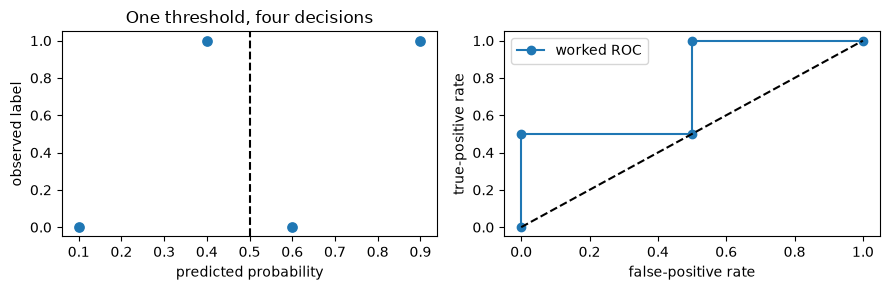

In [2]:
y_demo = np.array([0, 0, 1, 1]); p_demo = np.array([.1, .6, .4, .9])
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].scatter(p_demo, y_demo, s=45)
axes[0].axvline(.5, linestyle="--", color="black")
axes[0].set(xlabel="predicted probability", ylabel="observed label", title="One threshold, four decisions")
axes[1].plot([0, 0, .5, .5, 1], [0, .5, .5, 1, 1], "o-", label="worked ROC")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set(xlabel="false-positive rate", ylabel="true-positive rate"); axes[1].legend()
fig.tight_layout(); plt.show()

### Exercise 01.05.09 — Compare ranking, calibration, and decisions

**Type:** Experimental · **Answer:** Code

Generate 600 standard-normal logits with seed 60, draw labels from their sigmoid probabilities, and compare those probabilities with sigmoid(3×logit). Plot reliability diagrams with eight bins and ROC curves. Use a .5 threshold for decisions.

**Expected outcome:** actual probability metrics, equal rankings and decisions, and finite-sample calibration caveats.

In [ ]:
# Your code for Exercise 01.05.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.09**

Multiplication by a positive constant preserves score order and sign. It changes confidence.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.09**

This depends on `probability_metrics`, `classification_metrics`, and `binary_curves`. The sharpened forecasts need not have worse empirical loss for every finite sample; the population proper-scoring argument and actual observed scores are different statements.

~~~python
rng = np.random.default_rng(60); logits = rng.normal(size=600)
truth = 1 / (1 + np.exp(-logits)); labels = rng.binomial(1, truth)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for name, p in [("generating probabilities", truth), ("sharpened", 1/(1+np.exp(-3*logits)))]:
    result = probability_metrics(labels, p, bins=8); table = result['calibration']; valid = table[:, 0] > 0
    axes[0].plot(table[valid, 1], table[valid, 2], "o-", label=name)
    _, fpr, tpr, _, auc = binary_curves(labels, p)
    axes[1].plot(fpr, tpr, label=name)
    print(name, result['clipped_log_loss'], result['brier'], auc, classification_metrics(labels, p)['accuracy'])
axes[0].plot([0,1], [0,1], "k--"); axes[0].set(xlabel="mean forecast", ylabel="observed fraction")
axes[1].set(xlabel="FPR", ylabel="TPR")
for ax in axes: ax.legend()
fig.tight_layout(); plt.show()
~~~

</details>

### Exercise 01.05.10 — Quantify conditional evaluation uncertainty

**Type:** Experimental · **Answer:** Code

For the fixed predictions in the preceding experiment, bootstrap label/prediction pairs 600 times with seed 61 and calculate a percentile interval for mean Brier loss. What uncertainty sources are omitted?

**Expected outcome:** a measured interval with its sampling unit and conditional interpretation.

In [ ]:
# Your code for Exercise 01.05.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.10**

Resample pair indices, not labels and predictions independently. Do not refit or reselect in this experiment.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.10**

This depends on `labels` and `truth` from the preceding experiment. It estimates iid evaluation-sample uncertainty conditional on the fitted forecast procedure. It does not include training, model-selection, distribution-shift, or calibration-fitting variation. Bootstrap coverage is approximate.

~~~python
rng = np.random.default_rng(61)
per_row = (truth - labels)**2
estimates = np.array([per_row[rng.integers(0, len(per_row), len(per_row))].mean() for _ in range(600)])
print("Brier and conditional percentile interval", per_row.mean(), np.quantile(estimates, [.025, .975]))
plt.hist(estimates, bins=25); plt.xlabel("resampled mean Brier loss"); plt.ylabel("count"); plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### Exercise 01.05.11 — Find leakage beyond labels

**Type:** Critical · **Answer:** Markdown

A team standardizes all rows before CV, tests 100 penalty settings, chooses a threshold on test labels, and reports the best test score with CV standard deviation as its confidence interval. Identify each unsupported step and repair the protocol.

**Expected outcome:** preprocessing isolation, a selection boundary, and a valid uncertainty interpretation.

**Your response to Exercise 01.05.11**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.11**

Overlapping CV fits are not independent test samples. Selection effort matters even when each fit is correct.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.11**

Fit scaling only on each training fold and later on the full training partition. Use training CV for the fixed penalty grid, validation for the threshold, and a fresh untouched test set for final reporting. If the old test has already guided choices, it is validation data. CV spread describes fold-score variation; it is not a confidence interval after adaptive selection. A paired bootstrap on fresh test rows can describe conditional sampling uncertainty, while repeated refitting or nested protocols address other questions. Report the grid and decision cost to expose selection effort.

</details>

## 8. Review questions and knowledge checks

### Exercise 01.05.12 — Interpret a metric edge case

**Type:** Conceptual · **Answer:** Markdown

A sample contains only negative labels and all predictions are below .5. Which decision metrics are defined under this chapter's convention? Can ROC AUC be reported? Can Brier loss still be evaluated?

**Expected outcome:** explicit undefined values without silently inventing successes.

**Your response to Exercise 01.05.12**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.05.12**

Write every denominator from counts. Ranking requires a positive-negative pair.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.05.12**

Accuracy is one. Precision and recall are undefined (zero denominators), and F1 is undefined because 2TP+FP+FN=0. ROC AUC is undefined because no positive-negative pairs exist. Brier and clipped log loss are still computable for finite valid probabilities, but this sample cannot assess performance on positives. A perfect accuracy here is a statement about the observed class mix, not evidence of useful detection.

</details>

## 9. Summary and next learning steps

Explain what each metric measures; implement shape-safe baselines, metrics and fold-local preprocessing; verify hand values, ties and degenerate cases; evaluate a frozen model with declared uncertainty limits. Complete the [ML pipeline project](../../projects/01-ml-pipeline/ml-pipeline.ipynb). Stage 02 later extends the same protocol across classical algorithms; the existing [neural-network material](../04-neural-networks/perceptron.ipynb) is already usable after Stage 01.